# January 2026 wind forecast error analysis

**Question.** The day-ahead desk buys power on D-1 to cover demand on D. How far can it trust the national wind forecast it has at that moment, and how much cover should it hold against wind falling short?

**Data.** Elexon FUELHH (wind outturn, half-hourly) and WINDFOR (national wind forecast, hourly), delivery days 1 Jan – 1 Feb 2026. The notebook reads the same snapshot and uses the same selection code as the web app (`backend/app`), so every number here matches the dashboard.

**Conventions.** `error = forecast − actual` (positive means wind was over-forecast and the desk would be short). Lead time / horizon = target time − forecast publish time. Times are UTC, which equals UK time in January.

In [1]:
import sys
from datetime import time, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "backend"))
from app.config import Settings
from app.forecasting import align, horizon_cutoff
from app.analytics import daily_records, day_energy
from app.store import WindDataStore

settings = Settings(data_source="snapshot")
ds = WindDataStore(settings).get()

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
FORECAST, ACTUAL, SHORT = "#138a84", "#33409a", "#c8741e"
print(f"Actual half-hours: {len(ds.actuals):,}   forecast rows (0–48h lead): {len(ds.forecasts):,}")

Actual half-hours: 1,536   forecast rows (0–48h lead): 12,256


## 1. Data checks

In [2]:
act = pd.Series(ds.actuals, name="actual").sort_index()
expected = pd.date_range(settings.window_start, settings.window_end, freq="30min", inclusive="left")
print("Missing actual half-hours:", len(expected.difference(act.index)))

runs = sorted({p for t in ds.forecasts.targets for p in ds.forecasts.publish_times_for(t)})
run_hours = pd.Series([r.strftime("%H:%M") for r in runs]).value_counts().sort_index()
print("Forecast runs:", len(runs))
print("Publish times of day (UTC):", ", ".join(run_hours.index))
act.describe().round(0).to_frame().T

Missing actual half-hours: 0
Forecast runs: 272
Publish times of day (UTC): 02:30, 04:30, 07:30, 09:30, 11:30, 12:25, 15:30, 18:30, 22:30


,count,mean,std,min,25%,50%,75%,max
actual,1536.0,11411.0,4206.0,1695.0,8051.0,11736.0,15198.0,17805.0


WINDFOR is issued eight times a day and each run covers hourly targets up to roughly two days ahead. Outturn is complete for every half hour. Because forecasts are hourly, error metrics use the hourly targets where both values exist.

## 2. How error grows with lead time

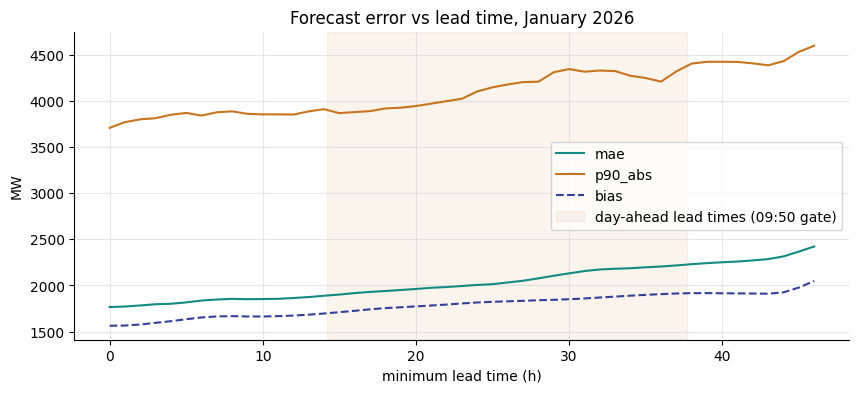

,n,mae,rmse,bias,p50_abs,p90_abs,p99_abs
horizon_h,,,,,,,
0.0,768,1766.0,2253.0,1564.0,1368.0,3708.0,6328.0
6.0,768,1837.0,2320.0,1654.0,1514.0,3840.0,6128.0
12.0,768,1864.0,2347.0,1674.0,1498.0,3851.0,6208.0
24.0,768,2005.0,2482.0,1815.0,1676.0,4101.0,6255.0
36.0,768,2205.0,2709.0,1906.0,1927.0,4208.0,6730.0
46.0,480,2422.0,2966.0,2049.0,2050.0,4596.0,7572.0


In [3]:
def pairs_frame(cutoff, start=settings.window_start, end=settings.window_end):
    rows = [
        (p.time, p.actual, p.forecast.generation, (p.time - p.forecast.publish_time).total_seconds() / 3600)
        for p in align(ds.actuals, ds.forecasts, start, end, cutoff)
        if p.is_pair
    ]
    df = pd.DataFrame(rows, columns=["time", "actual", "forecast", "lead_h"]).set_index("time")
    df["error"] = df.forecast - df.actual
    return df

rows = []
for h in np.arange(0, 47, 1.0):
    e = pairs_frame(horizon_cutoff(h)).error
    rows.append({"horizon_h": h, "n": len(e), "mae": e.abs().mean(), "rmse": np.sqrt((e**2).mean()),
                 "bias": e.mean(), "p50_abs": e.abs().quantile(0.5), "p90_abs": e.abs().quantile(0.9),
                 "p99_abs": e.abs().quantile(0.99)})
by_h = pd.DataFrame(rows).set_index("horizon_h")

ax = by_h[["mae", "p90_abs", "bias"]].plot(color=[FORECAST, SHORT, ACTUAL], style=["-", "-", "--"])
ax.axvspan(14.2, 37.7, color=SHORT, alpha=0.08, label="day-ahead lead times (09:50 gate)")
ax.set(xlabel="minimum lead time (h)", ylabel="MW", title="Forecast error vs lead time, January 2026")
ax.legend(); plt.show()
by_h.loc[[0, 6, 12, 24, 36, 46]].round(0)

Error rises steadily with lead time, but the striking feature is the **bias line sitting close to the MAE line**: most of the error is a systematic over-forecast, not random scatter.

## 3. The forecast the desk actually trades on (09:50 gate on D-1)

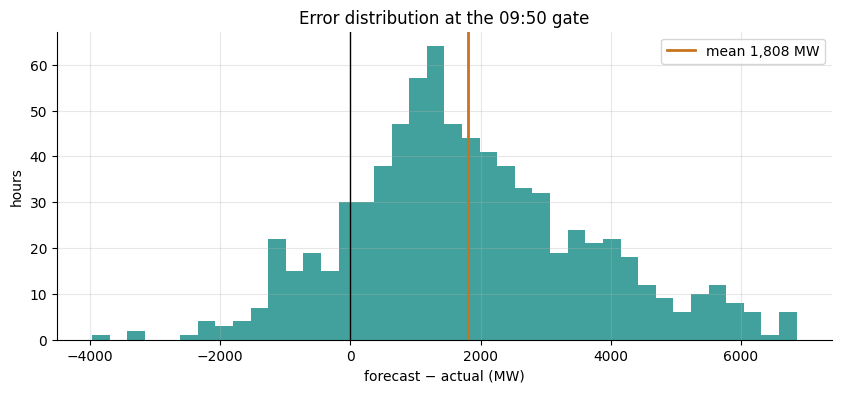

,periods,MAE,RMSE,bias,median error,P90 |error|,P99 |error|,WAPE %,share over-forecast %
09:50 gate,768.0,2066.8,2575.3,1807.5,1622.5,4333.7,6211.7,18.1,84.8


In [4]:
GATE = time(9, 50)
recs = daily_records(ds, settings, GATE)
gate_df = pd.concat([
    pd.DataFrame([(p.time, p.actual, p.forecast.generation) for p in pts if p.is_pair],
                 columns=["time", "actual", "forecast"]).assign(day=day)
    for day, _, pts in recs
]).set_index("time")
gate_df["error"] = gate_df.forecast - gate_df.actual
e = gate_df.error
summary = pd.Series({
    "periods": len(e), "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()), "bias": e.mean(),
    "median error": e.median(), "P90 |error|": e.abs().quantile(0.9), "P99 |error|": e.abs().quantile(0.99),
    "WAPE %": e.abs().sum() / gate_df.actual.sum() * 100, "share over-forecast %": (e > 0).mean() * 100,
}).round(1)
fig, ax = plt.subplots()
ax.hist(e, bins=40, color=FORECAST, alpha=0.8)
ax.axvline(0, color="k", lw=1); ax.axvline(e.mean(), color=SHORT, lw=2, label=f"mean {e.mean():,.0f} MW")
ax.set(xlabel="forecast − actual (MW)", ylabel="hours", title="Error distribution at the 09:50 gate"); ax.legend(); plt.show()
summary.to_frame("09:50 gate").T

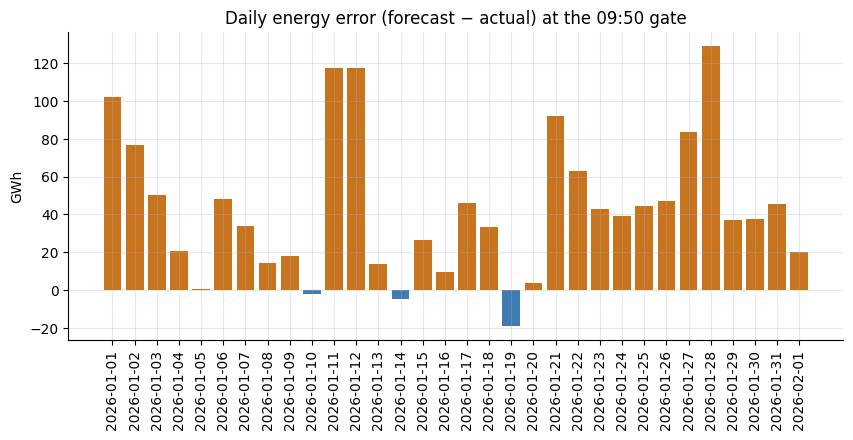

Over-forecast on 29 of 32 days; mean daily error 43.4 GWh; worst 129.0 GWh on 2026-01-28


In [5]:
# Same definition as the app: mean MW over the day x day length (actuals half-hourly, forecasts hourly)
daily_mwh = pd.DataFrame(
    [(day, *day_energy(pts)[1:]) for day, _, pts in recs], columns=["day", "forecast", "actual"]
).set_index("day")
daily_mwh["error"] = daily_mwh.forecast - daily_mwh.actual
fig, ax = plt.subplots()
ax.bar(daily_mwh.index.astype(str), daily_mwh.error / 1000, color=np.where(daily_mwh.error > 0, SHORT, "#3e7cb1"))
ax.set(ylabel="GWh", title="Daily energy error (forecast − actual) at the 09:50 gate"); ax.tick_params(axis="x", rotation=90)
plt.show()
print(f"Over-forecast on {(daily_mwh.error > 0).sum()} of {len(daily_mwh)} days; "
      f"mean daily error {daily_mwh.error.mean()/1000:,.1f} GWh; worst {daily_mwh.error.max()/1000:,.1f} GWh on {daily_mwh.error.idxmax()}")

### 3b. Does a later gate help?

In [6]:
gates = {}
for g in [time(9, 50), time(12, 0), time(15, 30)]:
    pairs = [(p.forecast.generation - p.actual) for _, _, pts in daily_records(ds, settings, g) for p in pts if p.is_pair]
    s_ = pd.Series(pairs)
    gates[g.strftime("%H:%M")] = {"MAE": s_.abs().mean(), "bias": s_.mean(), "P90 |error|": s_.abs().quantile(0.9)}
pd.DataFrame(gates).T.round(0)

,MAE,bias,P90 |error|
09:50,2067.0,1808.0,4334.0
12:00,1958.0,1765.0,3970.0
15:30,1933.0,1786.0,4006.0


## 4. When and where the forecast misses

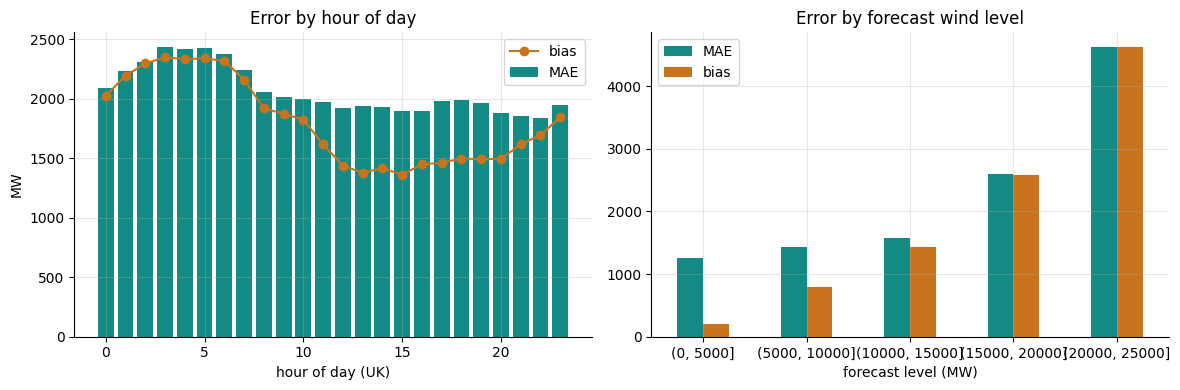

,MAE,bias,n
forecast,,,
"(0, 5000]",1257.0,201.0,31
"(5000, 10000]",1427.0,790.0,210
"(10000, 15000]",1573.0,1439.0,206
"(15000, 20000]",2596.0,2578.0,276
"(20000, 25000]",4626.0,4626.0,45


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour = gate_df.groupby(gate_df.index.hour).error
axes[0].bar(by_hour.mean().index, by_hour.apply(lambda x: x.abs().mean()), color=FORECAST, label="MAE")
axes[0].plot(by_hour.mean().index, by_hour.mean(), color=SHORT, marker="o", label="bias")
axes[0].set(xlabel="hour of day (UK)", ylabel="MW", title="Error by hour of day"); axes[0].legend()

bins = pd.cut(gate_df.forecast, bins=[0, 5000, 10000, 15000, 20000, 25000])
by_level = gate_df.groupby(bins, observed=True).error
lvl = pd.DataFrame({"MAE": by_level.apply(lambda x: x.abs().mean()), "bias": by_level.mean(), "n": by_level.size()})
lvl[["MAE", "bias"]].plot.bar(ax=axes[1], color=[FORECAST, SHORT])
axes[1].set(xlabel="forecast level (MW)", title="Error by forecast wind level"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
lvl.round(0)

Errors are larger when high wind is forecast. That is consistent with outturn being held back at high output (for example by network constraints or curtailment), which a forecast of *available* wind would not anticipate. We have not verified the cause with BOA/curtailment data; it is the main hypothesis to test next.

## 5. Would a simple bias correction help?

To avoid scoring on data we trained on, each day's forecast is corrected using the mean error of the **other** days only (leave-one-day-out).

In [8]:
day_bias = gate_df.groupby("day").error.agg(["sum", "count"])
tot_sum, tot_n = day_bias["sum"].sum(), day_bias["count"].sum()
loo = (tot_sum - day_bias["sum"]) / (tot_n - day_bias["count"])
corrected = gate_df.forecast - gate_df.day.map(loo)
ce = corrected - gate_df.actual
comp = pd.DataFrame({
    "raw forecast": [e.abs().mean(), np.sqrt((e**2).mean()), e.mean(), e.abs().quantile(0.9)],
    "bias-corrected (LOO)": [ce.abs().mean(), np.sqrt((ce**2).mean()), ce.mean(), ce.abs().quantile(0.9)],
}, index=["MAE", "RMSE", "bias", "P90 |error|"]).round(0)
comp["change %"] = ((comp.iloc[:, 1] / comp.iloc[:, 0] - 1) * 100).round(1)
comp

,raw forecast,bias-corrected (LOO),change %
MAE,2067.0,1478.0,-28.5
RMSE,2575.0,1877.0,-27.1
bias,1808.0,-0.0,-100.0
P90 |error|,4334.0,3105.0,-28.4


## 6. How much wind can the desk rely on?

In [9]:
res = gate_df.actual - gate_df.forecast
q10, q90 = res.quantile([0.1, 0.9])
daily_res = daily_mwh.actual - daily_mwh.forecast
d10 = daily_res.quantile(0.1)
reliable = pd.Series({
    "P10 residual per hour (MW)": q10,
    "P90 residual per hour (MW)": q90,
    "P10 daily energy residual (GWh)": d10 / 1000,
    "Wind exceeded 90% of the time in January (MW)": act.quantile(0.10),
    "Wind exceeded 50% of the time (MW)": act.quantile(0.50),
}).round(1)
reliable.to_frame("value")

,value
P10 residual per hour (MW),-4333.7
P90 residual per hour (MW),468.2
P10 daily energy residual (GWh),-101.2
Wind exceeded 90% of the time in January (MW),5432.0
Wind exceeded 50% of the time (MW),11735.5


**Reading the table.** Without a forecast, January wind was above the 10th-percentile level 90% of the time; that is the unconditional floor. With the gate forecast in hand, the desk can be ~90% confident that actual wind will be at least `forecast + P10 residual` in a given hour, or `forecast energy + P10 daily residual` over the day. The dashboard reports exactly this as **"Wind you can count on (P10)"**, and the gap to the raw forecast as **"Cover to hold for wind risk"**.

## 7. Conclusions

1. **The forecast is biased high.** At the 09:50 gate it over-forecast wind on almost every January day, by roughly 1.8 GW on average. Taken at face value it leaves the desk short.
2. **Bias, not noise, dominates.** Bias is close to MAE at every lead time; a leave-one-day-out bias correction cuts MAE substantially (table in §5).
3. **Error grows with lead time,** from about 1.8 GW MAE for the freshest run to about 2.2 GW at the far end of the day-ahead window. Moving the decision from 09:50 to 15:30 on D-1 uses a fresher run and lowers MAE by about 6% (§3b); the bias remains.
4. **Size cover from the error distribution, not the point forecast.** Planning to the P10 level gives ~90% confidence that wind will at least meet the plan.

**Limitations.** One month of winter data; P10/P90 estimated from 32 days is indicative only. Root cause of the bias (curtailment vs forecast model vs metering scope) is not established from these two datasets alone.